In [1]:
import pandas as pd

rules = pd.read_csv("data/rule_items.csv")
handmade = pd.read_csv("data/handmade_items.csv")
data = pd.concat([rules, handmade], ignore_index=True)

print(len(data), "items")
data.sample(10)

469 items


,item,category,source
411,college id,documents,handmade
32,Thermal base layer,clothing,rules
89,Electrolyte packets,misc,rules
339,paracetamol,toiletries,handmade
377,bluetooth speaker,electronics,handmade
441,coffee sachets,misc,handmade
396,passport photos,documents,handmade
437,khakhra,misc,handmade
425,water bottle,misc,handmade
418,car rental papers,documents,handmade


category
clothing       154
misc           121
toiletries      84
electronics     62
documents       48
Name: count, dtype: int64

Duplicates: 3


<Axes: title={'center': 'Items per category'}, xlabel='category'>

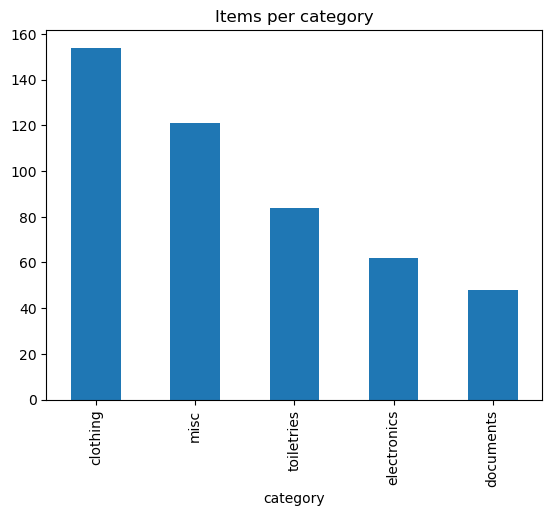

In [2]:
print(data["category"].value_counts())
print()
print("Duplicates:", data["item"].str.lower().duplicated().sum())

data["category"].value_counts().plot(kind="bar", title="Items per category")

In [3]:
data["clean"] = data["item"].str.lower().str.strip()

dupes = data[data["clean"].duplicated(keep=False)].sort_values("clean")
print(dupes[["item", "category", "source"]])

data = data.drop_duplicates(subset="clean", keep="first").reset_index(drop=True)
print()
print(len(data), "items after removing duplicates")

              item    category    source
116  First aid kit        misc     rules
465  first aid kit        misc  handmade
175    Neck pillow        misc     rules
432    neck pillow        misc  handmade
0       Toothbrush  toiletries     rules
306     toothbrush  toiletries  handmade

466 items after removing duplicates


In [4]:
from sklearn.model_selection import train_test_split

X = data["clean"]
y = data["category"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(len(X_train), "items to learn from")
print(len(X_test), "items hidden for testing")
print()
print(y_test.value_counts())

372 items to learn from
94 items hidden for testing

category
clothing       31
misc           24
toiletries     17
electronics    12
documents      10
Name: count, dtype: int64


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

model = make_pipeline(
    TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4)),
    LogisticRegression(class_weight="balanced", max_iter=1000),
)

model.fit(X_train, y_train)

accuracy = model.score(X_test, y_test)
print(f"Accuracy on unseen items: {accuracy:.0%}")

Accuracy on unseen items: 69%


In [6]:
from sklearn.metrics import classification_report

predictions = model.predict(X_test)
print(classification_report(y_test, predictions))

results = pd.DataFrame({"item": X_test, "actual": y_test, "predicted": predictions})
mistakes = results[results["actual"] != results["predicted"]]
print(len(mistakes), "mistakes")
mistakes

              precision    recall  f1-score   support

    clothing       0.83      0.81      0.82        31
   documents       0.50      0.50      0.50        10
 electronics       0.70      0.58      0.64        12
        misc       0.64      0.75      0.69        24
  toiletries       0.62      0.59      0.61        17

    accuracy                           0.69        94
   macro avg       0.66      0.65      0.65        94
weighted avg       0.69      0.69      0.69        94

29 mistakes


,item,actual,predicted
277,blazer,clothing,electronics
456,tissues,misc,clothing
329,tweezers,toiletries,clothing
323,makeup remover,toiletries,clothing
81,insect repellent (deet / picaridin),toiletries,documents
421,pen for immigration form,documents,toiletries
403,foreign currency,documents,misc
177,paper maps (backup),documents,misc
190,athletic tape,misc,electronics
86,wide-brim sun hat,clothing,toiletries


In [7]:
from sklearn.pipeline import make_union

features = make_union(
    TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4)),
    TfidfVectorizer(analyzer="word", ngram_range=(1, 2)),
)

model2 = make_pipeline(features, LogisticRegression(class_weight="balanced", max_iter=1000))
model2.fit(X_train, y_train)

print(f"Letters only:      {model.score(X_test, y_test):.0%}")
print(f"Letters + words:   {model2.score(X_test, y_test):.0%}")

Letters only:      69%
Letters + words:   73%


In [8]:
   %pip install sentence-transformers

Note: you may need to restart the kernel to use updated packages.


In [ ]:
%pip install --resume-retries 10 --timeout 120 sentence-transformers

In [10]:
from sentence_transformers import SentenceTransformer

encoder = SentenceTransformer("all-MiniLM-L6-v2")

E_train = encoder.encode(X_train.tolist())
E_test = encoder.encode(X_test.tolist())
print(E_train.shape)

model3 = LogisticRegression(class_weight="balanced", max_iter=1000)
model3.fit(E_train, y_train)

print(f"Letters + words:  {model2.score(X_test, y_test):.0%}")
print(f"Embeddings:       {model3.score(E_test, y_test):.0%}")

tricky = ["euros", "mouse", "nintendo switch", "pjs", "uno cards", "camera bag", "tweezers", "blazer"]
print(dict(zip(tricky, model3.predict(encoder.encode(tricky)))))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

(372, 384)
Letters + words:  73%
Embeddings:       85%
{'euros': 'documents', 'mouse': 'electronics', 'nintendo switch': 'electronics', 'pjs': 'clothing', 'uno cards': 'documents', 'camera bag': 'electronics', 'tweezers': 'misc', 'blazer': 'clothing'}


In [11]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X_all = data["clean"]
y_all = data["category"]
E_all = encoder.encode(X_all.tolist())

scores_words = cross_val_score(model2, X_all, y_all, cv=cv)
scores_embed = cross_val_score(LogisticRegression(class_weight="balanced", max_iter=1000), E_all, y_all, cv=cv)

print(f"Letters + words: {scores_words.mean():.0%}  (varies by ±{scores_words.std():.0%})")
print(f"Embeddings:      {scores_embed.mean():.0%}  (varies by ±{scores_embed.std():.0%})")

Letters + words: 76%  (varies by ±4%)
Embeddings:      82%  (varies by ±4%)


In [12]:
import json, os

final = LogisticRegression(class_weight="balanced", max_iter=1000)
final.fit(E_all, y_all)

check_items = ["type c cable", "sunnies", "aadhaar card", "face wash", "hoodie"]
check_probs = final.predict_proba(encoder.encode(check_items))

export = {
    "embedding_model": "sentence-transformers/all-MiniLM-L6-v2",
    "classes": final.classes_.tolist(),
    "coef": final.coef_.round(6).tolist(),
    "intercept": final.intercept_.round(6).tolist(),
    "cv_accuracy": round(float(scores_embed.mean()), 3),
    "trained_on": len(y_all),
    "checks": [
        {"item": item, "probs": p.round(4).tolist()}
        for item, p in zip(check_items, check_probs)
    ],
}

os.makedirs("../server/ml", exist_ok=True)
with open("../server/ml/item_sorter.json", "w") as f:
    json.dump(export, f)

for item, p in zip(check_items, check_probs):
    best = p.argmax()
    print(f"{item:15} → {final.classes_[best]:12} ({p[best]:.0%} sure)")

type c cable    → electronics  (70% sure)
sunnies         → clothing     (32% sure)
aadhaar card    → documents    (79% sure)
face wash       → toiletries   (83% sure)
hoodie          → clothing     (63% sure)


In [13]:
for C in [0.1, 1, 10, 30, 100]:
    scores = cross_val_score(
        LogisticRegression(C=C, class_weight="balanced", max_iter=2000), E_all, y_all, cv=cv
    )
    probe = LogisticRegression(C=C, class_weight="balanced", max_iter=2000).fit(E_all, y_all)
    sure = probe.predict_proba(encoder.encode(["kajal", "kurta", "airpods"])).max(axis=1)
    print(f"C={C:<5} accuracy {scores.mean():.0%} (±{scores.std():.0%})   confidence on kajal/kurta/airpods: {[f'{p:.0%}' for p in sure]}")

C=0.1   accuracy 78% (±4%)   confidence on kajal/kurta/airpods: ['24%', '23%', '31%']
C=1     accuracy 82% (±4%)   confidence on kajal/kurta/airpods: ['37%', '44%', '63%']
C=10    accuracy 84% (±3%)   confidence on kajal/kurta/airpods: ['68%', '81%', '88%']
C=30    accuracy 84% (±3%)   confidence on kajal/kurta/airpods: ['83%', '91%', '94%']
C=100   accuracy 83% (±3%)   confidence on kajal/kurta/airpods: ['93%', '96%', '98%']


In [14]:
best_C = 10
scores_final = cross_val_score(
    LogisticRegression(C=best_C, class_weight="balanced", max_iter=2000), E_all, y_all, cv=cv
)

final = LogisticRegression(C=best_C, class_weight="balanced", max_iter=2000)
final.fit(E_all, y_all)

check_probs = final.predict_proba(encoder.encode(check_items))
export.update({
    "coef": final.coef_.round(6).tolist(),
    "intercept": final.intercept_.round(6).tolist(),
    "C": best_C,
    "cv_accuracy": round(float(scores_final.mean()), 3),
    "checks": [{"item": i, "probs": p.round(4).tolist()} for i, p in zip(check_items, check_probs)],
})
with open("../server/ml/item_sorter.json", "w") as f:
    json.dump(export, f)

print(f"Saved. Cross-validated accuracy: {scores_final.mean():.0%}")
for item, p in zip(check_items, check_probs):
    print(f"{item:15} → {final.classes_[p.argmax()]:12} ({p.max():.0%} sure)")

Saved. Cross-validated accuracy: 84%
type c cable    → electronics  (92% sure)
sunnies         → misc         (67% sure)
aadhaar card    → documents    (95% sure)
face wash       → toiletries   (97% sure)
hoodie          → clothing     (90% sure)
